In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import os

In [2]:
def getData(observables, filename, treename):
    file = uproot.open(filename)
    if (len(file.keys())>0 and treename in file.keys()[0]):
        return (file[treename]).arrays(observables, library='pd')
    else:
        print(treename, "not found in", filename)
        return -1

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['font.size'] = 15

# Read in event trees

In [7]:
observables = ['runnumber','eventnumber','centrality','refmult','rho']

In [10]:
df_mb_array = []
filepath = '/gpfs/gibbs/project/havener/ys668/rc/isobar/mb_evt_day118/'
nevt = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "event_tree")
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_mb_array.append(df_temp)
    print('read in', df_temp.shape[0], 'events')
    nevt += df_temp.shape[0]
df_mb = pd.concat([df for df in df_mb_array])
print('total number of events: ', df_mb.shape[0])

reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_218.root
read in 214063 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_120.root
read in 200245 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_15.root
read in 220730 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_395.root
read in 213405 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_2.root
read in 220868 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_430.root
read in 166591 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_4.root
read in 195507 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_247.root
read in 209525 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_484.root
read in 145468 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_134.root
read in 225380 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_354.root
read in 110507 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_450.

read in 186285 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_0.root
read in 196456 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_365.root
read in 183881 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_127.root
read in 221670 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_119.root
read in 110437 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_378.root
read in 213003 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_186.root
read in 224038 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_311.root
read in 174229 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_84.root
read in 18535 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_443.root
read in 223895 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_483.root
read in 132518 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_269.root
read in 222771 events
reading in file event.AC9AD1D64AC9D1

read in 187614 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_113.root
read in 188154 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_278.root
read in 211614 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_397.root
read in 201692 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_70.root
read in 220165 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_64.root
read in 210610 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_133.root
read in 224370 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_417.root
read in 162781 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_40.root
read in 216549 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_339.root
read in 22802 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_239.root
read in 185105 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_452.root
read in 190427 events
reading in file event.AC9AD1D64AC9D1

read in 203512 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_401.root
read in 208257 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_441.root
read in 204265 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_55.root
read in 203238 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_88.root
read in 23520 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_122.root
read in 202635 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_42.root
read in 142957 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_360.root
read in 146804 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_101.root
read in 217927 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_508.root
read in 221776 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_475.root
read in 181183 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_49.root
read in 209136 events
reading in file event.AC9AD1D64AC9D1F

read in 221332 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_109.root
read in 220889 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_388.root
read in 174350 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_305.root
read in 196069 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_335.root
read in 7266 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_403.root
read in 225633 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_94.root
read in 32042 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_255.root
read in 220239 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_344.root
read in 40399 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_364.root
read in 219497 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_0.root
read in 224070 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_193.root
read in 224077 events
reading in file event.AC9AD1D64AC9D1FD4

read in 224434 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_468.root
read in 198386 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_34.root
read in 210373 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_320.root
read in 19912 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_166.root
read in 223886 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_502.root
read in 186211 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_329.root
read in 24679 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_158.root
read in 223749 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_204.root
read in 162161 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_454.root
read in 119607 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_412.root
read in 168665 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_152.root
read in 223458 events
reading in file event.AC9AD1D64AC9D

read in 194923 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_253.root
read in 220753 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_25.root
read in 146873 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_44.root
read in 64781 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_144.root
read in 216300 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_191.root
read in 224117 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_268.root
read in 220555 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_85.root
read in 224620 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_367.root
read in 189320 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_108.root
read in 225869 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_32.root
read in 101412 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_377.root
read in 213708 events
reading in file event.AC9AD1D64AC9D1F

In [11]:
df_118 = df_mb

In [14]:
df_mb_array = []
filepath = '/gpfs/gibbs/project/havener/ys668/rc/isobar/mb_evt_day115_117/'
nevt = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "event_tree")
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_mb_array.append(df_temp)
    print('read in', df_temp.shape[0], 'events')
    nevt += df_temp.shape[0]
df_mb = pd.concat([df for df in df_mb_array])
print('total number of events: ', df_mb.shape[0])

reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_534.root
read in 165671 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_619.root
read in 154772 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_42.root
read in 205939 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_833.root
read in 220788 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_64.root
read in 225864 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_698.root
read in 42407 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_739.root
read in 214962 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_291.root
read in 208926 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_686.root
read in 25403 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_814.root
read in 219085 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_568.root
read in 24627 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_770.

read in 208435 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_280.root
read in 220876 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_394.root
read in 205523 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_415.root
read in 220050 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_244.root
read in 192991 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_787.root
read in 207899 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_475.root
read in 220430 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_668.root
read in 20092 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_682.root
read in 25220 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_673.root
read in 23398 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_656.root
read in 115228 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_197.root
read in 220151 events
reading in file event.6BA75F9149A4E

read in 197192 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_222.root
read in 220565 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_115.root
read in 210438 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_627.root
read in 122068 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_605.root
read in 73512 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_19.root
read in 223169 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_172.root
read in 183792 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_713.root
read in 108011 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_636.root
read in 176782 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_669.root
read in 20427 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_837.root
read in 221059 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_36.root
read in 193187 events
reading in file event.6BA75F9149A4E3

read in 210184 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_722.root
read in 186222 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_746.root
read in 221120 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_373.root
read in 218719 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_293.root
read in 218137 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_544.root
read in 155274 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_697.root
read in 128568 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_335.root
read in 220480 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_817.root
read in 211987 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_397.root
read in 215694 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_261.root
read in 172725 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_548.root
read in 16926 events
reading in file event.6BA75F9149A

read in 208661 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_287.root
read in 206104 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_691.root
read in 31353 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_381.root
read in 213750 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_189.root
read in 218139 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_719.root
read in 224171 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_630.root
read in 121939 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_620.root
read in 171840 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_569.root
read in 23749 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_396.root
read in 219522 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_54.root
read in 219112 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_119.root
read in 211592 events
reading in file event.6BA75F9149A4E

read in 200748 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_827.root
read in 217246 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_467.root
read in 225164 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_334.root
read in 220033 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_813.root
read in 160433 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_136.root
read in 220141 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_15.root
read in 219530 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_677.root
read in 22204 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_98.root
read in 222561 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_777.root
read in 212530 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_247.root
read in 213190 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_333.root
read in 219741 events
reading in file event.6BA75F9149A4E

read in 200279 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_283.root
read in 222098 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_303.root
read in 212322 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_108.root
read in 221432 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_214.root
read in 177143 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_92.root
read in 202242 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_46.root
read in 208200 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_736.root
read in 213149 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_24.root
read in 218874 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_137.root
read in 209581 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_533.root
read in 211698 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_794.root
read in 159377 events
reading in file event.6BA75F9149A4E

read in 221172 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_647.root
read in 48043 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_29.root
read in 167456 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_411.root
read in 191758 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_192.root
read in 174300 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_672.root
read in 19583 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_508.root
read in 224043 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_339.root
read in 185618 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_859.root
read in 210336 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_170.root
read in 215673 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_213.root
read in 154122 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_236.root
read in 209730 events
reading in file event.6BA75F9149A4E

read in 210030 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_118.root
read in 223846 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_871.root
read in 77903 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_855.root
read in 177924 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_594.root
read in 20501 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_148.root
read in 222858 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_82.root
read in 219687 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_32.root
read in 172489 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_182.root
read in 215541 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_484.root
read in 213547 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_801.root
read in 220799 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_858.root
read in 221472 events
reading in file event.6BA75F9149A4E3

read in 218494 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_680.root
read in 105552 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_646.root
read in 221269 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_145.root
read in 217462 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_735.root
read in 216241 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_93.root
read in 190196 events
reading in file event.6BA75F9149A4E34DF6AA608C33BAEF08_248.root
read in 219503 events
total number of events:  156550275


In [15]:
df_115_117 = df_mb

In [8]:
df_mb_array = []
filepath = '/vast/palmer/scratch/havener/ys668/useful/mb_evt_day112_114/'
nevt = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "event_tree")
    if (isinstance(df_temp, pd.core.frame.DataFrame) == False):
        continue
    df_mb_array.append(df_temp)
    print('read in', df_temp.shape[0], 'events')
    nevt += df_temp.shape[0]
df_mb = pd.concat([df for df in df_mb_array])
print('total number of events: ', df_mb.shape[0])

reading in file event.90873BA764EDD869B0E21039541007C2_0.root
read in 221716 events
reading in file event.90873BA764EDD869B0E21039541007C2_1.root
read in 179870 events
reading in file event.90873BA764EDD869B0E21039541007C2_10.root
read in 223059 events
reading in file event.90873BA764EDD869B0E21039541007C2_100.root
read in 219702 events
reading in file event.90873BA764EDD869B0E21039541007C2_1000.root
read in 221470 events
reading in file event.90873BA764EDD869B0E21039541007C2_1001.root
read in 126096 events
reading in file event.90873BA764EDD869B0E21039541007C2_1002.root
read in 29025 events
reading in file event.90873BA764EDD869B0E21039541007C2_1003.root
read in 24981 events
reading in file event.90873BA764EDD869B0E21039541007C2_1004.root
read in 18325 events
reading in file event.90873BA764EDD869B0E21039541007C2_1005.root
read in 62029 events
reading in file event.90873BA764EDD869B0E21039541007C2_1006.root
read in 202804 events
reading in file event.90873BA764EDD869B0E21039541007C2_1

read in 177881 events
reading in file event.90873BA764EDD869B0E21039541007C2_1081.root
read in 147846 events
reading in file event.90873BA764EDD869B0E21039541007C2_1082.root
read in 199714 events
reading in file event.90873BA764EDD869B0E21039541007C2_1083.root
read in 213329 events
reading in file event.90873BA764EDD869B0E21039541007C2_1084.root
read in 191020 events
reading in file event.90873BA764EDD869B0E21039541007C2_1085.root
read in 170683 events
reading in file event.90873BA764EDD869B0E21039541007C2_1086.root
read in 208005 events
reading in file event.90873BA764EDD869B0E21039541007C2_1087.root
read in 225170 events
reading in file event.90873BA764EDD869B0E21039541007C2_1088.root
read in 216779 events
reading in file event.90873BA764EDD869B0E21039541007C2_1089.root
read in 212452 events
reading in file event.90873BA764EDD869B0E21039541007C2_109.root
read in 221651 events
reading in file event.90873BA764EDD869B0E21039541007C2_1090.root
read in 146102 events
reading in file event.

read in 167037 events
reading in file event.90873BA764EDD869B0E21039541007C2_1167.root
read in 111360 events
reading in file event.90873BA764EDD869B0E21039541007C2_1168.root
read in 190093 events
reading in file event.90873BA764EDD869B0E21039541007C2_1169.root
read in 214668 events
reading in file event.90873BA764EDD869B0E21039541007C2_117.root
read in 215370 events
reading in file event.90873BA764EDD869B0E21039541007C2_1170.root
read in 227922 events
reading in file event.90873BA764EDD869B0E21039541007C2_1171.root
read in 228957 events
reading in file event.90873BA764EDD869B0E21039541007C2_1172.root
read in 226957 events
reading in file event.90873BA764EDD869B0E21039541007C2_1173.root
read in 226481 events
reading in file event.90873BA764EDD869B0E21039541007C2_1174.root
read in 201802 events
reading in file event.90873BA764EDD869B0E21039541007C2_1175.root
read in 227958 events
reading in file event.90873BA764EDD869B0E21039541007C2_1176.root
read in 212363 events
reading in file event.

read in 227163 events
reading in file event.90873BA764EDD869B0E21039541007C2_1252.root
read in 227840 events
reading in file event.90873BA764EDD869B0E21039541007C2_1253.root
read in 227599 events
reading in file event.90873BA764EDD869B0E21039541007C2_1254.root
read in 216651 events
reading in file event.90873BA764EDD869B0E21039541007C2_1255.root
read in 216007 events
reading in file event.90873BA764EDD869B0E21039541007C2_1256.root
read in 228399 events
reading in file event.90873BA764EDD869B0E21039541007C2_1257.root
read in 216908 events
reading in file event.90873BA764EDD869B0E21039541007C2_1258.root
read in 213600 events
reading in file event.90873BA764EDD869B0E21039541007C2_1259.root
read in 213877 events
reading in file event.90873BA764EDD869B0E21039541007C2_126.root
read in 213761 events
reading in file event.90873BA764EDD869B0E21039541007C2_1260.root
read in 228024 events
reading in file event.90873BA764EDD869B0E21039541007C2_1261.root
read in 225798 events
reading in file event.

read in 207875 events
reading in file event.90873BA764EDD869B0E21039541007C2_1337.root
read in 217281 events
reading in file event.90873BA764EDD869B0E21039541007C2_1338.root
read in 215486 events
reading in file event.90873BA764EDD869B0E21039541007C2_1339.root
read in 216282 events
reading in file event.90873BA764EDD869B0E21039541007C2_134.root
read in 221497 events
reading in file event.90873BA764EDD869B0E21039541007C2_1340.root
read in 228640 events
reading in file event.90873BA764EDD869B0E21039541007C2_1341.root
read in 228234 events
reading in file event.90873BA764EDD869B0E21039541007C2_1342.root
read in 228424 events
reading in file event.90873BA764EDD869B0E21039541007C2_1343.root
read in 228462 events
reading in file event.90873BA764EDD869B0E21039541007C2_1344.root
read in 211526 events
reading in file event.90873BA764EDD869B0E21039541007C2_1345.root
read in 228758 events
reading in file event.90873BA764EDD869B0E21039541007C2_1346.root
read in 224650 events
reading in file event.

read in 182645 events
reading in file event.90873BA764EDD869B0E21039541007C2_1423.root
read in 205761 events
reading in file event.90873BA764EDD869B0E21039541007C2_1424.root
read in 205895 events
reading in file event.90873BA764EDD869B0E21039541007C2_1425.root
read in 160193 events
reading in file event.90873BA764EDD869B0E21039541007C2_1426.root
read in 227408 events
reading in file event.90873BA764EDD869B0E21039541007C2_1427.root
read in 205896 events
reading in file event.90873BA764EDD869B0E21039541007C2_1428.root
read in 217498 events
reading in file event.90873BA764EDD869B0E21039541007C2_1429.root
read in 167425 events
reading in file event.90873BA764EDD869B0E21039541007C2_143.root
read in 225680 events
reading in file event.90873BA764EDD869B0E21039541007C2_1430.root
read in 229298 events
reading in file event.90873BA764EDD869B0E21039541007C2_1431.root
read in 224439 events
reading in file event.90873BA764EDD869B0E21039541007C2_1432.root
read in 222738 events
reading in file event.

... (9 outputs left out)

read in 157024 events
reading in file event.90873BA764EDD869B0E21039541007C2_661.root
read in 190326 events
reading in file event.90873BA764EDD869B0E21039541007C2_662.root
read in 202150 events
reading in file event.90873BA764EDD869B0E21039541007C2_663.root
read in 211387 events
reading in file event.90873BA764EDD869B0E21039541007C2_664.root
read in 222088 events
reading in file event.90873BA764EDD869B0E21039541007C2_665.root
read in 210238 events
reading in file event.90873BA764EDD869B0E21039541007C2_666.root
read in 211883 events
reading in file event.90873BA764EDD869B0E21039541007C2_667.root
read in 211814 events
reading in file event.90873BA764EDD869B0E21039541007C2_668.root
read in 223234 events
reading in file event.90873BA764EDD869B0E21039541007C2_669.root
read in 222833 events
reading in file event.90873BA764EDD869B0E21039541007C2_67.root
read in 209916 events
reading in file event.90873BA764EDD869B0E21039541007C2_670.root
read in 209090 events
reading in file event.90873BA764E

read in 173021 events
reading in file event.90873BA764EDD869B0E21039541007C2_748.root
read in 196911 events
reading in file event.90873BA764EDD869B0E21039541007C2_749.root
read in 164104 events
reading in file event.90873BA764EDD869B0E21039541007C2_75.root
read in 218866 events
reading in file event.90873BA764EDD869B0E21039541007C2_750.root
read in 189686 events
reading in file event.90873BA764EDD869B0E21039541007C2_751.root
read in 208616 events
reading in file event.90873BA764EDD869B0E21039541007C2_752.root
read in 201702 events
reading in file event.90873BA764EDD869B0E21039541007C2_753.root
read in 196623 events
reading in file event.90873BA764EDD869B0E21039541007C2_754.root
read in 168214 events
reading in file event.90873BA764EDD869B0E21039541007C2_755.root
read in 191024 events
reading in file event.90873BA764EDD869B0E21039541007C2_756.root
read in 225755 events
reading in file event.90873BA764EDD869B0E21039541007C2_757.root
read in 201877 events
reading in file event.90873BA764E

read in 222472 events
reading in file event.90873BA764EDD869B0E21039541007C2_833.root
read in 222011 events
reading in file event.90873BA764EDD869B0E21039541007C2_834.root
read in 222964 events
reading in file event.90873BA764EDD869B0E21039541007C2_835.root
read in 178560 events
reading in file event.90873BA764EDD869B0E21039541007C2_836.root
read in 222476 events
reading in file event.90873BA764EDD869B0E21039541007C2_837.root
read in 221186 events
reading in file event.90873BA764EDD869B0E21039541007C2_838.root
read in 198851 events
reading in file event.90873BA764EDD869B0E21039541007C2_839.root
read in 190241 events
reading in file event.90873BA764EDD869B0E21039541007C2_84.root
read in 188793 events
reading in file event.90873BA764EDD869B0E21039541007C2_840.root
read in 140815 events
reading in file event.90873BA764EDD869B0E21039541007C2_841.root
read in 206096 events
reading in file event.90873BA764EDD869B0E21039541007C2_842.root
read in 215649 events
reading in file event.90873BA764E

read in 41638 events
reading in file event.90873BA764EDD869B0E21039541007C2_921.root
read in 31701 events
reading in file event.90873BA764EDD869B0E21039541007C2_922.root
read in 31708 events
reading in file event.90873BA764EDD869B0E21039541007C2_923.root
read in 8553 events
reading in file event.90873BA764EDD869B0E21039541007C2_924.root
read in 23219 events
reading in file event.90873BA764EDD869B0E21039541007C2_925.root
read in 12946 events
reading in file event.90873BA764EDD869B0E21039541007C2_926.root
read in 12006 events
reading in file event.90873BA764EDD869B0E21039541007C2_927.root
read in 20417 events
reading in file event.90873BA764EDD869B0E21039541007C2_928.root
read in 85470 events
reading in file event.90873BA764EDD869B0E21039541007C2_929.root
read in 157623 events
reading in file event.90873BA764EDD869B0E21039541007C2_93.root
read in 222717 events
reading in file event.90873BA764EDD869B0E21039541007C2_930.root
read in 154798 events
reading in file event.90873BA764EDD869B0E21

In [9]:
df_112_114 = df_mb

In [11]:
df_112_114

,runnumber,eventnumber,centrality,refmult,rho
0,19112002,2663902,13,187.0,21.274849
1,19112002,2664062,2,14.0,1.555714
2,19112002,2663995,9,100.0,13.933297
3,19112002,2664014,7,65.0,11.580250
4,19112002,2663927,14,215.0,30.910975
...,...,...,...,...,...
67480,19112015,2189559,4,27.0,1.948862
67481,19112015,2189521,9,85.0,11.642942
67482,19112015,2189531,6,48.0,4.942924
67483,19112015,2189633,1,11.0,0.000000


In [12]:
df_112_114.drop_duplicates(subset=['runnumber','eventnumber']).shape[0]

328736258

# Combine event trees

In [18]:
df_mb = pd.concat([df_112_114, df_115_117, df_118])
print(df_mb.shape[0])

601028617


# Plot background density

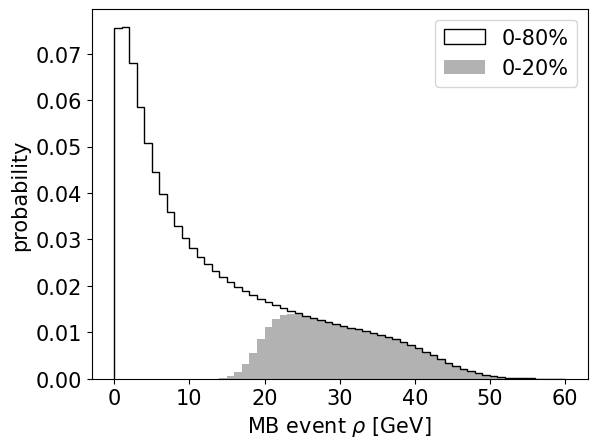

In [19]:
plt.hist(df_mb['rho'], bins=np.arange(0,61), histtype='step', weights=np.ones(df_mb.shape[0])*(1/df_mb.shape[0]), label='0-80%', color='k')
plt.hist(df_mb[df_mb.centrality>=12]['rho'], bins=np.arange(0,61), alpha=0.3, weights=np.ones(df_mb[df_mb.centrality>=12].shape[0])*(1/df_mb.shape[0]), label='0-20%', color='k')
plt.xlabel(r'event $\rho$ [GeV$/c$]')
plt.ylabel('probability')
plt.legend()

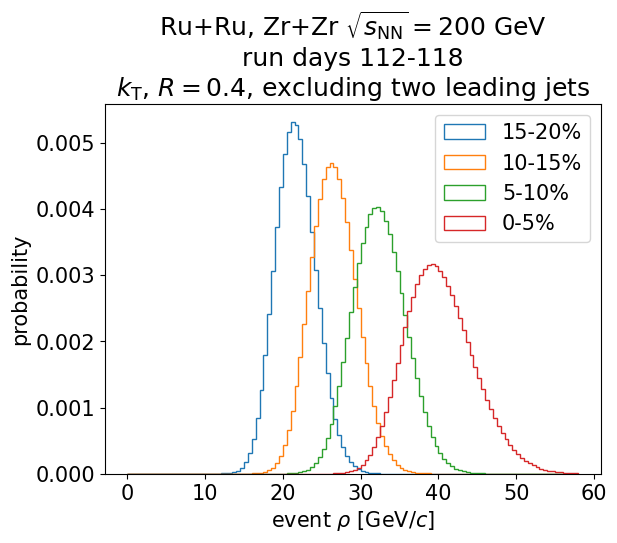

In [25]:
plt.hist(df_mb[df_mb.centrality==12]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==12].shape[0])*(1/df_mb.shape[0]), label='15-20%')
plt.hist(df_mb[df_mb.centrality==13]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==13].shape[0])*(1/df_mb.shape[0]), label='10-15%')
plt.hist(df_mb[df_mb.centrality==14]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==14].shape[0])*(1/df_mb.shape[0]), label='5-10%')
plt.hist(df_mb[df_mb.centrality==15]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==15].shape[0])*(1/df_mb.shape[0]), label='0-5%')
plt.xlabel(r'event $\rho$ [GeV/$c$]')
plt.title(r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV'+'\nrun days 112-118\n$k_{\mathrm{T}}$, $R=0.4$, excluding two leading jets')
plt.ylabel('probability')
plt.legend()

(1e-06, 1)

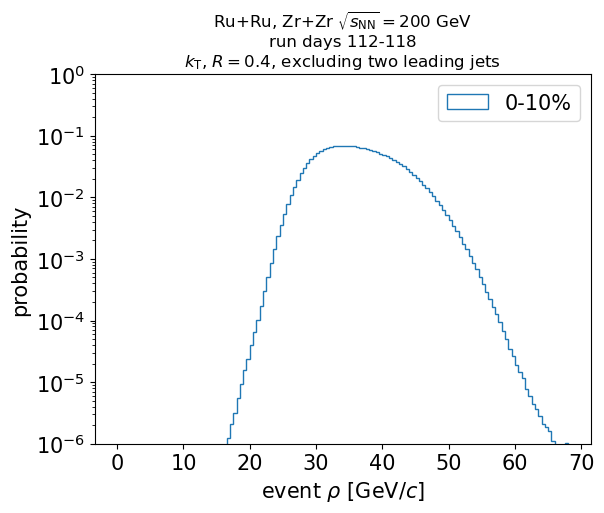

In [18]:
plt.hist(df_mb[df_mb.centrality>=14]['rho'], bins=np.arange(0,68.5,0.5), histtype='step', density=True, label='0-10%')
plt.xlabel(r'event $\rho$ [GeV/$c$]')
plt.title(r'Ru+Ru, Zr+Zr $\sqrt{s_{\mathrm{NN}}}=200$ GeV'+'\nrun days 112-118\n$k_{\mathrm{T}}$, $R=0.4$, excluding two leading jets', fontsize=12)
plt.ylabel('probability')
plt.legend()
plt.yscale('log')
plt.xticks(np.arange(0,80,10))
plt.ylim(1e-6,1)

In [21]:
print(np.average(df_mb[df_mb.centrality==12]['rho']), np.std(df_mb[df_mb.centrality==12]['rho']))

21.669859 2.6033266


In [22]:
print(np.average(df_mb[df_mb.centrality==13]['rho']), np.std(df_mb[df_mb.centrality==13]['rho']))

26.533674 2.9677012


In [23]:
print(np.average(df_mb[df_mb.centrality==14]['rho']), np.std(df_mb[df_mb.centrality==14]['rho']))

32.41361 3.3755333


In [24]:
print(np.average(df_mb[df_mb.centrality==15]['rho']), np.std(df_mb[df_mb.centrality==15]['rho']))

40.179665 4.414815


# Plot refmult

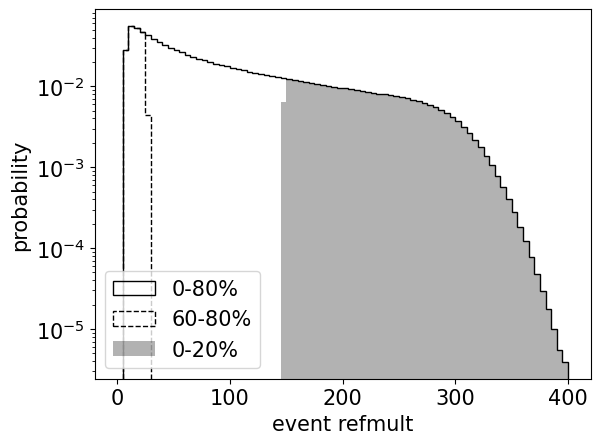

In [19]:
plt.hist(df_mb['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb.shape[0])*(1/df_mb.shape[0]), label='0-80%', color='k')
plt.hist(df_mb[df_mb.centrality<=3]['refmult'], bins=np.arange(0,405,5), histtype='step', linestyle='dashed', weights=np.ones(df_mb[df_mb.centrality<=3].shape[0])*(1/df_mb.shape[0]), label='60-80%', color='k')
plt.hist(df_mb[df_mb.centrality>=12]['refmult'], bins=np.arange(0,405,5), alpha=0.3, weights=np.ones(df_mb[df_mb.centrality>=12].shape[0])*(1/df_mb.shape[0]), label='0-20%', color='k')
plt.xlabel('event refmult')
plt.ylabel('probability')
plt.yscale('log')
plt.legend()

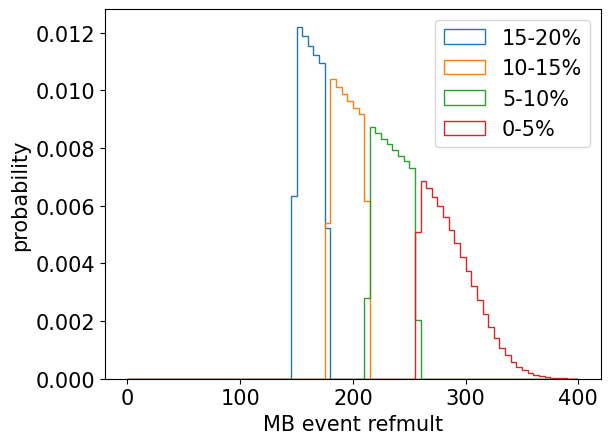

In [32]:
plt.hist(df_mb[df_mb.centrality==12]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==12].shape[0])*(1/df_mb.shape[0]), label='15-20%')
plt.hist(df_mb[df_mb.centrality==13]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==13].shape[0])*(1/df_mb.shape[0]), label='10-15%')
plt.hist(df_mb[df_mb.centrality==14]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==14].shape[0])*(1/df_mb.shape[0]), label='5-10%')
plt.hist(df_mb[df_mb.centrality==15]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==15].shape[0])*(1/df_mb.shape[0]), label='0-5%')
plt.xlabel('MB event refmult')
plt.ylabel('probability')
plt.legend()

# High tower triggered data

In [26]:
observables = ['runnumber','eventnumber','centrality','rho']

In [27]:
filename = '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/ht_evt_49run57.root'
treename = 'event_tree'

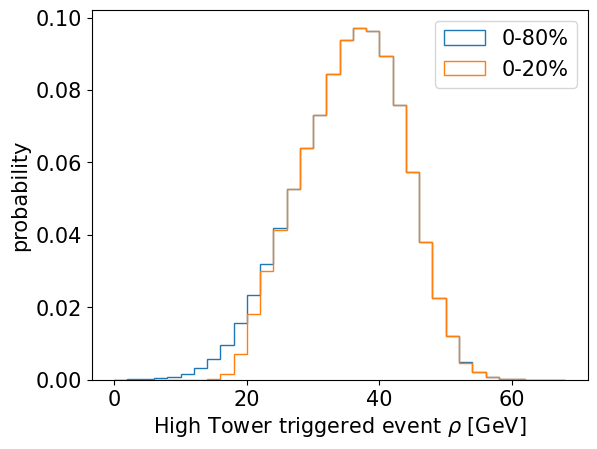

In [56]:
plt.hist(df['rho'], bins=np.arange(0,70,2), histtype='step', weights=np.ones(df.shape[0])*(1/df.shape[0]), label='0-80%')
plt.hist(df[df.centrality>=12]['rho'], bins=np.arange(0,70,2), histtype='step', weights=np.ones(df[df.centrality>=12].shape[0])*(1/df.shape[0]), label='0-20%')
plt.xlabel(r'High Tower triggered event $\rho$ [GeV]')
plt.ylabel('probability')
plt.legend()

In [57]:
print(np.average(df[df.centrality>=12]['rho']), np.std(df[df.centrality>=12]['rho']))

36.00869 7.353644
